#SEGUNDO AVANCE
construcción de base de datos

La predicción se realiza al cierre de cada año (t). Por tanto, las variables explicativas utilizan únicamente información observada entre enero y diciembre de (t), y la etiqueta observa si la misma ruta vuelve a operar durante los 12 meses siguientes, es decir, durante el año (t+1).

Se consideran disponibles para entrenamiento y evaluación los años 2021–2024. El año 2025 no se utiliza para entrenamiento porque no existe todavía una ventana completa de seguimiento de 12 meses posterior a diciembre de 2025.

Definición de ruta
Se considera que A–B y B–A pertenecen a la misma ruta, porque el objetivo económico es identificar la continuidad de la conexión entre dos aeropuertos, independientemente del sentido del vuelo. La ruta se identifica ordenando los dos códigos de aeropuerto.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve
)

RANDOM_STATE = 42
DATA_PATH = Path("data/datos_aerocivil.xlsx")

if not DATA_PATH.exists():
    candidatos = list(Path(".").glob("*.xlsx"))
    if candidatos:
        DATA_PATH = candidatos[0]
    else:
        raise FileNotFoundError(
            "No se encontró el archivo Excel. Colóquelo en data/datos_aerocivil.xlsx "
            "o ajuste DATA_PATH en esta celda."
        )

print("Archivo utilizado:", DATA_PATH)

Archivo utilizado: Estadísticas_de_Oferta_y_Demanda_-_Transporte_Pasajeros_Diciembre_2025__2_.xlsx


Carga de base de datos

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="BasedeDatos")

print("Dimensiones:", raw.shape)
display(raw.head())
print("\nColumnas:")
print(raw.columns.tolist())

Dimensiones: (173080, 46)


,Fecha,Sigla Empresa,Nombre,Origen,Nombre2,Ciudad Origen,Departamento Origen,Pais Origen,Continente Origen,Destino,...,Sillas Ofrecidas por KM,Pasajeros Promedio Movilizados por KM,Horas Bloque Cerrado,LARGO,HORAS,MINUTOS,Total Minutos,Total Horas,Total Horas / Número de Vuelos,Unnamed: 45
0,2021-01-01,0EC,SAE,A06,EL ENCANTO,EL ENCANTO,AMAZONAS,COLOMBIA,SURAMERICA,LET,...,0.0,1357.939499,1.92,4,"1,9",2,116.0,1.933333,1.933333,NaN
1,2021-01-01,0EC,SAE,A07,MORICHAL VIEJO,SAN JOSÉ DEL GUAVIARE,GUAVIARE,COLOMBIA,SURAMERICA,SJE,...,0.0,875.353406,1.00,1,1,0,60.0,1.000000,1.000000,NaN
2,2021-01-01,0EC,SAE,A13,MIRITI PARANA,MIRITÍ - PARANÁ,AMAZONAS,COLOMBIA,SURAMERICA,LET,...,0.0,2311.431355,1.50,3,1.5,0,90.0,1.500000,1.500000,NaN
3,2021-01-01,0EC,SAE,BMG,BARRANCOMINAS,BARRANCOMINAS,GUAINÍA,COLOMBIA,SURAMERICA,IDA,...,0.0,645.11545,0.75,4,"0,7",5,47.0,0.783333,0.783333,NaN
4,2021-01-01,0EC,SAE,CRU,CARURÚ,CARURÚ,VAUPÉS,COLOMBIA,SURAMERICA,SJE,...,0.0,1376.260553,0.92,4,"0,9",2,56.0,0.933333,0.933333,NaN



Columnas:
['Fecha', 'Sigla Empresa', 'Nombre', 'Origen', 'Nombre2', 'Ciudad Origen', 'Departamento Origen', 'Pais Origen', 'Continente Origen', 'Destino', 'Nombre3', 'Ciudad Destino', 'Departamento Destino', 'Pais Destino', 'Continente Destino', 'Tipo de Equipo', 'Tipo Vuelo', 'Tráfico', 'Número de Vuelos', 'Horas Bloque', 'Sillas Ofrecidas', 'Pasajeros A Bordo', 'Pasajeros Tránsito', 'Carga Ofrecida (Kg.)', 'Carga + Correo A Bordo (Kg.)', 'Carga Tránsito (Kg.)', 'Tráfico (N/I) 2', 'Tipo Vuelo 2', 'Tipo Vuelo (Regular - No Regular)', 'Año', 'Mes', 'Latitud Origen', 'Longitud Origen', 'Latitud Destino', 'Longitud Destino', 'Distancia Ortodrómica (Punto a Punto)', 'Sillas Ofrecidas por KM', 'Pasajeros Promedio Movilizados por KM', 'Horas Bloque Cerrado', 'LARGO', 'HORAS', 'MINUTOS', 'Total Minutos', 'Total Horas', 'Total Horas / Número de Vuelos', 'Unnamed: 45']


Filtro de estudio

- trafico nacional
- vuelo regular

La combinación se implementa con `Tráfico (N/I) 2 == Nacional` y `Tipo Vuelo 2 == Regular`.

La base original tiene 173.080 registros. El filtro aplicado aquí permite comprobar directamente cuántas observaciones pertenecen al universo nacional regular.

In [4]:
df = raw.copy()
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")

df = df[
    (df["Tráfico (N/I) 2"] == "Nacional") &
    (df["Tipo Vuelo 2"] == "Regular")
].copy()

print("Filas después del filtro:", len(df))
print("Aerolíneas:", df["Sigla Empresa"].nunique())
print("Años:", sorted(df["Año"].dropna().unique()))

Filas después del filtro: 41207
Aerolíneas: 34
Años: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


Definición de la ruta y revisión de dupicados

La base contiene varias observaciones para una misma conexión porque registra diferentes aerolíneas, aeronaves y meses.

Para responder la pregunta económica se agrega posteriormente a **ruta–año**. A–B y B–A se consideran una sola ruta.

In [5]:
df["mes_num"] = df["Fecha"].dt.month

df["ruta_id"] = np.where(
    df["Origen"].astype(str) < df["Destino"].astype(str),
    df["Origen"].astype(str) + "-" + df["Destino"].astype(str),
    df["Destino"].astype(str) + "-" + df["Origen"].astype(str)
)

df["ruta_nombre"] = np.where(
    df["Origen"].astype(str) < df["Destino"].astype(str),
    df["Ciudad Origen"].astype(str) + " - " + df["Ciudad Destino"].astype(str),
    df["Ciudad Destino"].astype(str) + " - " + df["Ciudad Origen"].astype(str)
)

print("Rutas únicas en todo el periodo:", df["ruta_id"].nunique())
print("Aerolíneas únicas:", df["Sigla Empresa"].nunique())

Rutas únicas en todo el periodo: 345
Aerolíneas únicas: 34


construcción de la etiqueta

Para una ruta activa en el año (t):

fecha de predicción: 31 de diciembre del año (t);
ventana de seguimiento: enero–diciembre del año (t+1);
cierre = 1: no aparece ningún registro de operación regular de esa ruta durante (t+1);
sobrevive = 0: la ruta vuelve a operar al menos una vez durante (t+1).
Esta definición evita usar información posterior al momento de predicción. También evita confundir una pausa mensual o estacional con un cierre.

In [6]:
# Conjunto de rutas activas por año
rutas_por_ano = {
    int(anio): set(grupo["ruta_id"])
    for anio, grupo in df.groupby("Año")
}

# Ruta-año: agregación inicial
ruta_anio = (
    df.groupby(["Año", "ruta_id", "ruta_nombre"])
      .agg(
          pasajeros=("Pasajeros A Bordo", "sum"),
          sillas=("Sillas Ofrecidas", "sum"),
          vuelos=("Número de Vuelos", "sum"),
          horas_bloque=("Horas Bloque", "sum"),
          distancia=("Distancia Ortodrómica (Punto a Punto)", "first"),
          meses_activos=("mes_num", "nunique"),
          aerolineas=("Sigla Empresa", "nunique"),
          tipos_aeronave=("Tipo de Equipo", "nunique")
      )
      .reset_index()
)

ruta_anio["cierre_12m"] = ruta_anio.apply(
    lambda r: (
        np.nan if int(r["Año"]) == 2025
        else int(r["ruta_id"] not in rutas_por_ano.get(int(r["Año"]) + 1, set()))
    ),
    axis=1
)

print("Ruta-año total:", ruta_anio.shape)
display(ruta_anio.groupby("Año").agg(
    rutas=("ruta_id", "size"),
    cierres=("cierre_12m", "sum"),
    tasa_cierre=("cierre_12m", "mean")
))

Ruta-año total: (1012, 12)


,rutas,cierres,tasa_cierre
Año,,,
2021,187,41.0,0.219251
2022,219,57.0,0.260274
2023,194,37.0,0.190722
2024,205,37.0,0.180488
2025,207,0.0,NaN


Variables explicativas
Se construyen variables que existirían al cierre del año (t):

pasajeros y sillas acumulados;
número de vuelos;
horas bloque;
distancia;
meses activos;
número de aerolíneas;
factor de ocupación anual;
pasajeros por vuelo;
vuelos promedio por mes activo;
tendencia anual del factor de ocupación.
El factor de ocupación se calcula como pasajeros / sillas. Cuando no existen sillas ofrecidas, se deja como faltante para evitar una división artificial.

In [7]:
ruta_anio["factor_ocupacion"] = np.where(
    ruta_anio["sillas"] > 0,
    ruta_anio["pasajeros"] / ruta_anio["sillas"],
    np.nan
)

ruta_anio["pax_por_vuelo"] = np.where(
    ruta_anio["vuelos"] > 0,
    ruta_anio["pasajeros"] / ruta_anio["vuelos"],
    np.nan
)

ruta_anio["vuelos_mes"] = np.where(
    ruta_anio["meses_activos"] > 0,
    ruta_anio["vuelos"] / ruta_anio["meses_activos"],
    np.nan
)

# Tendencia del factor de ocupación: pendiente anual aproximada.
mensual = (
    df.groupby(["Año", "ruta_id", "Fecha"])
      .agg(
          pax=("Pasajeros A Bordo", "sum"),
          sillas=("Sillas Ofrecidas", "sum")
      )
      .reset_index()
)

mensual["factor_ocupacion"] = np.where(
    mensual["sillas"] > 0,
    mensual["pax"] / mensual["sillas"],
    np.nan
)

def pendiente_ocupacion(grupo):
    g = grupo.sort_values("Fecha").copy()
    g = g.dropna(subset=["factor_ocupacion"])
    if len(g) < 2:
        return np.nan
    x = g["Fecha"].map(pd.Timestamp.toordinal).to_numpy()
    y = g["factor_ocupacion"].to_numpy()
    return np.polyfit(x, y, 1)[0] * 365

tendencia = (
    mensual.groupby(["Año", "ruta_id"])
           .apply(pendiente_ocupacion, include_groups=False)
           .rename("tendencia_ocupacion")
           .reset_index()
)

ruta_anio = ruta_anio.merge(tendencia, on=["Año", "ruta_id"], how="left")

features = [
    "pasajeros", "sillas", "vuelos", "horas_bloque", "distancia",
    "meses_activos", "aerolineas", "factor_ocupacion",
    "pax_por_vuelo", "vuelos_mes", "tendencia_ocupacion"
]

display(ruta_anio[["Año", "ruta_id"] + features + ["cierre_12m"]].head())

,Año,ruta_id,pasajeros,sillas,vuelos,horas_bloque,distancia,meses_activos,aerolineas,factor_ocupacion,pax_por_vuelo,vuelos_mes,tendencia_ocupacion,cierre_12m
0,2021,9DI-IDA,964.0,1634,86,79.72,234.380762,10,1,0.589963,11.209302,8.6,-0.139551,0.0
1,2021,9DI-SJE,6.0,19,1,2.50,622.362357,1,1,0.315789,6.000000,1.0,NaN,1.0
2,2021,9MQ-CAO,0.0,0,3,2.27,51.005869,1,1,NaN,0.000000,3.0,NaN,1.0
3,2021,ACR-LCH,27.0,57,3,1.53,105.15995,3,1,0.473684,9.000000,1.0,-0.078193,1.0
4,2021,ACR-LET,8.0,19,1,1.67,483.600419,1,1,0.421053,8.000000,1.0,NaN,1.0


Tabla de comprobación solicitada
Antes de entrenar modelos se revisan ejemplos de ruta–año con:

fecha de predicción;
variables disponibles;
ventana de seguimiento;
etiqueta observada.
Esto permite verificar que la etiqueta no dependa de información posterior al corte.

In [8]:
muestra = ruta_anio[ruta_anio["Año"] <= 2024].copy()
muestra["fecha_prediccion"] = pd.to_datetime(muestra["Año"].astype(str) + "-12-31")
muestra["seguimiento_desde"] = pd.to_datetime((muestra["Año"] + 1).astype(str) + "-01-01")
muestra["seguimiento_hasta"] = pd.to_datetime((muestra["Año"] + 1).astype(str) + "-12-31")

columnas_muestra = [
    "Año", "ruta_id", "fecha_prediccion",
    "seguimiento_desde", "seguimiento_hasta",
    "pasajeros", "sillas", "vuelos", "meses_activos",
    "aerolineas", "factor_ocupacion", "distancia",
    "cierre_12m"
]

display(
    muestra.sort_values(["Año", "ruta_id"])[columnas_muestra].head(12)
)

,Año,ruta_id,fecha_prediccion,seguimiento_desde,seguimiento_hasta,pasajeros,sillas,vuelos,meses_activos,aerolineas,factor_ocupacion,distancia,cierre_12m
0,2021,9DI-IDA,2021-12-31,2022-01-01,2022-12-31,964.0,1634,86,10,1,0.589963,234.380762,0.0
1,2021,9DI-SJE,2021-12-31,2022-01-01,2022-12-31,6.0,19,1,1,1,0.315789,622.362357,1.0
2,2021,9MQ-CAO,2021-12-31,2022-01-01,2022-12-31,0.0,0,3,1,1,NaN,51.005869,1.0
3,2021,ACR-LCH,2021-12-31,2022-01-01,2022-12-31,27.0,57,3,3,1,0.473684,105.15995,1.0
4,2021,ACR-LET,2021-12-31,2022-01-01,2022-12-31,8.0,19,1,1,1,0.421053,483.600419,1.0
5,2021,ACR-SJE,2021-12-31,2022-01-01,2022-12-31,128.0,228,13,5,1,0.561404,354.655157,0.0
6,2021,ACR-SVI,2021-12-31,2022-01-01,2022-12-31,0.0,0,2,2,1,NaN,403.760389,1.0
7,2021,ADZ-BAQ,2021-12-31,2022-01-01,2022-12-31,47866.0,58536,417,12,4,0.817719,777.631395,0.0
8,2021,ADZ-BGA,2021-12-31,2022-01-01,2022-12-31,1327.0,1880,10,1,1,0.705851,1113.560087,0.0
9,2021,ADZ-BOG,2021-12-31,2022-01-01,2022-12-31,1034133.0,1217819,7202,12,5,0.849168,1207.673856,0.0


Desbalance de clases
La variable objetivo es binaria y el cierre no es la clase mayoritaria. Por eso la evaluación no se basará en accuracy. Se utilizarán precisión, recall, F1 y PR-AUC.

In [9]:
evaluacion = ruta_anio[ruta_anio["Año"] <= 2024].copy()

print(evaluacion["cierre_12m"].value_counts().rename(index={0:"Sobrevive",1:"Cierre"}))
print("\nProporción de cierres:", evaluacion["cierre_12m"].mean())

display(
    evaluacion.groupby("Año")
              .agg(
                  rutas=("ruta_id", "size"),
                  cierres=("cierre_12m", "sum"),
                  tasa_cierre=("cierre_12m", "mean")
              )
)

cierre_12m
Sobrevive    633
Cierre       172
Name: count, dtype: int64

Proporción de cierres: 0.21366459627329193


,rutas,cierres,tasa_cierre
Año,,,
2021,187,41.0,0.219251
2022,219,57.0,0.260274
2023,194,37.0,0.190722
2024,205,37.0,0.180488


Exploración inicial
Se observa la distribución de la etiqueta y una relación descriptiva entre el factor de ocupación y el cierre. Estos gráficos son descriptivos: no deben interpretarse como evidencia causal.

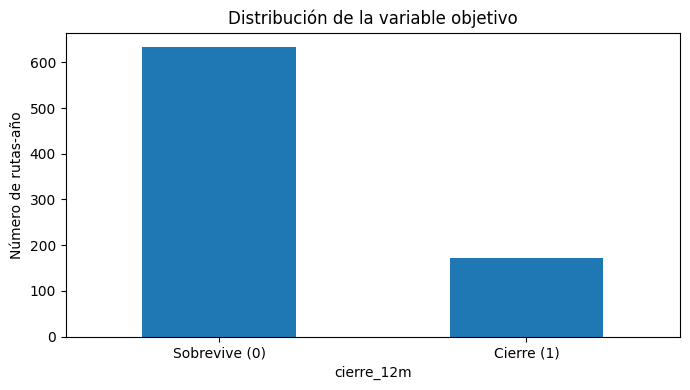

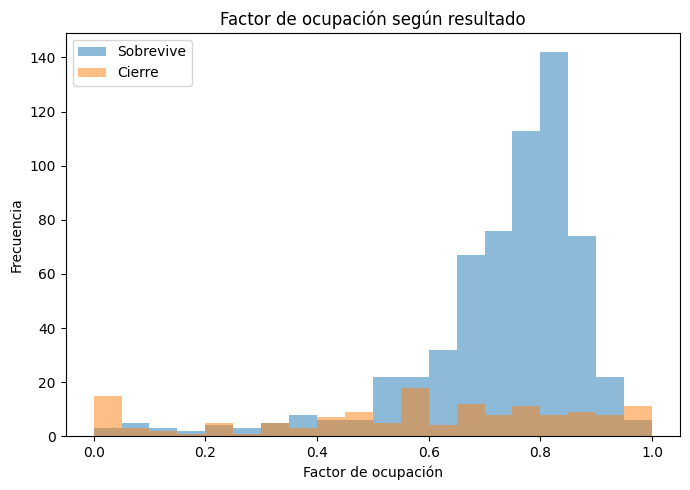

In [10]:
plt.figure(figsize=(7,4))
evaluacion["cierre_12m"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0,1], ["Sobrevive (0)", "Cierre (1)"], rotation=0)
plt.ylabel("Número de rutas-año")
plt.title("Distribución de la variable objetivo")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
for clase, nombre in [(0, "Sobrevive"), (1, "Cierre")]:
    vals = evaluacion.loc[evaluacion["cierre_12m"] == clase, "factor_ocupacion"].dropna()
    plt.hist(vals, bins=20, alpha=0.5, label=nombre)
plt.xlabel("Factor de ocupación")
plt.ylabel("Frecuencia")
plt.title("Factor de ocupación según resultado")
plt.legend()
plt.tight_layout()
plt.show()

Validación temporal
Se respeta el orden temporal:

Entrenamiento: 2021–2022
Validación: 2023
Prueba final: 2024
El año 2025 queda fuera porque todavía no tiene seguimiento completo de 12 meses.

La muestra de prueba no se utiliza para seleccionar variables, hiperparámetros o umbrales.




In [11]:
train = evaluacion[evaluacion["Año"].isin([2021, 2022])].copy()
val = evaluacion[evaluacion["Año"] == 2023].copy()
test = evaluacion[evaluacion["Año"] == 2024].copy()

X_train, y_train = train[features], train["cierre_12m"].astype(int)
X_val, y_val = val[features], val["cierre_12m"].astype(int)
X_test, y_test = test[features], test["cierre_12m"].astype(int)

print("Train:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Train: (406, 11)
Validación: (194, 11)
Prueba: (205, 11)


Línea base ingenua
La línea base predice siempre la clase mayoritaria: sobrevive (0).

Aunque esta regla puede tener una accuracy elevada, no detecta cierres y, por tanto, tiene recall cero para la clase de interés. Sirve como referencia mínima.

In [12]:
pred_base = np.zeros(len(y_test), dtype=int)

base_precision = precision_score(y_test, pred_base, zero_division=0)
base_recall = recall_score(y_test, pred_base, zero_division=0)
base_f1 = f1_score(y_test, pred_base, zero_division=0)
base_ap = y_test.mean()

print("Línea base")
print("Precision:", base_precision)
print("Recall:", base_recall)
print("F1:", base_f1)
print("PR-AUC / AP de referencia:", base_ap)
print("Matriz de confusión:")
print(confusion_matrix(y_test, pred_base))

Línea base
Precision: 0.0
Recall: 0.0
F1: 0.0
PR-AUC / AP de referencia: 0.18048780487804877
Matriz de confusión:
[[168   0]
 [ 37   0]]


Modelo 1: regresión logística
La regresión logística funciona como primera alternativa interpretable. Se utiliza class_weight="balanced" para evitar que la clase mayoritaria domine el entrenamiento.

La imputación y estandarización se realizan dentro del Pipeline, evitando calcular transformaciones con la muestra de prueba.

In [13]:
logit = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logit.fit(X_train, y_train)

proba_val_logit = logit.predict_proba(X_val)[:, 1]
print("PR-AUC validación:", average_precision_score(y_val, proba_val_logit))

PR-AUC validación: 0.6202964870242715


Selección del umbral en validación
El umbral no tiene por qué ser 0,5. Como una alerta de cierre busca no dejar pasar demasiadas rutas que efectivamente desaparecen, se revisa el equilibrio entre precisión y recall en la muestra de validación.

Aquí se selecciona el umbral que maximiza F1 en validación. El criterio puede modificarse si el equipo define un costo económico explícito para los falsos negativos.

In [14]:
umbrales = np.arange(0.20, 0.81, 0.01)
filas = []

for umbral in umbrales:
    pred = (proba_val_logit >= umbral).astype(int)
    filas.append({
        "umbral": umbral,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

tabla_umbral = pd.DataFrame(filas)
umbral_logit = float(tabla_umbral.loc[tabla_umbral["f1"].idxmax(), "umbral"])

display(tabla_umbral.sort_values("f1", ascending=False).head(10))
print("Umbral seleccionado:", umbral_logit)

,umbral,precision,recall,f1
50,0.70,0.561404,0.864865,0.680851
52,0.72,0.563636,0.837838,0.673913
49,0.69,0.551724,0.864865,0.673684
53,0.73,0.566038,0.810811,0.666667
51,0.71,0.553571,0.837838,0.666667
46,0.66,0.542373,0.864865,0.666667
48,0.68,0.542373,0.864865,0.666667
47,0.67,0.542373,0.864865,0.666667
45,0.65,0.533333,0.864865,0.659794
56,0.76,0.568627,0.783784,0.659091


Umbral seleccionado: 0.7000000000000004


Modelo 2: Random Forest

Se contrasta la regresión logística con un Random Forest. La finalidad no es utilizar un modelo más complejo por sí mismo, sino comprobar si relaciones no lineales y combinaciones entre variables mejoran la capacidad predictiva.

In [15]:
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)
proba_val_rf = rf.predict_proba(X_val)[:, 1]

print("PR-AUC validación Random Forest:",
      average_precision_score(y_val, proba_val_rf))

PR-AUC validación Random Forest: 0.6379618684098775


In [16]:
filas_rf = []

for umbral in umbrales:
    pred = (proba_val_rf >= umbral).astype(int)
    filas_rf.append({
        "umbral": umbral,
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0)
    })

tabla_umbral_rf = pd.DataFrame(filas_rf)
umbral_rf = float(tabla_umbral_rf.loc[tabla_umbral_rf["f1"].idxmax(), "umbral"])

display(tabla_umbral_rf.sort_values("f1", ascending=False).head(10))
print("Umbral RF seleccionado:", umbral_rf)

,umbral,precision,recall,f1
51,0.71,0.656250,0.567568,0.608696
50,0.70,0.656250,0.567568,0.608696
14,0.34,0.463768,0.864865,0.603774
45,0.65,0.611111,0.594595,0.602740
44,0.64,0.611111,0.594595,0.602740
47,0.67,0.611111,0.594595,0.602740
46,0.66,0.611111,0.594595,0.602740
12,0.32,0.457143,0.864865,0.598131
11,0.31,0.457143,0.864865,0.598131
13,0.33,0.457143,0.864865,0.598131


Umbral RF seleccionado: 0.7000000000000004


Comparación preliminar en validación
La comparación se realiza con las mismas particiones. Se reportan PR-AUC y F1 para la clase cierre.



In [17]:
def resumen_modelo(y, proba, umbral, nombre):
    pred = (proba >= umbral).astype(int)
    return {
        "Modelo": nombre,
        "PR-AUC": average_precision_score(y, proba),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0)
    }

comparacion_val = pd.DataFrame([
    resumen_modelo(y_val, proba_val_logit, umbral_logit, "Regresión logística"),
    resumen_modelo(y_val, proba_val_rf, umbral_rf, "Random Forest")
])

display(comparacion_val)

,Modelo,PR-AUC,Precision,Recall,F1
0,Regresión logística,0.620296,0.561404,0.864865,0.680851
1,Random Forest,0.637962,0.656250,0.567568,0.608696


Evaluación final en prueba 2024
Una vez fijados los modelos y umbrales usando entrenamiento + validación, se evalúan en 2024. Esta muestra no participa en decisiones de ajuste.

In [18]:
proba_test_logit = logit.predict_proba(X_test)[:, 1]
proba_test_rf = rf.predict_proba(X_test)[:, 1]

comparacion_test = pd.DataFrame([
    resumen_modelo(y_test, proba_test_logit, umbral_logit, "Regresión logística"),
    resumen_modelo(y_test, proba_test_rf, umbral_rf, "Random Forest")
])

comparacion_test.insert(1, "N_observaciones", len(y_test))
display(comparacion_test)

print("\nMatriz de confusión — Regresión logística")
print(confusion_matrix(y_test, (proba_test_logit >= umbral_logit).astype(int)))

print("\nMatriz de confusión — Random Forest")
print(confusion_matrix(y_test, (proba_test_rf >= umbral_rf).astype(int)))

,Modelo,N_observaciones,PR-AUC,Precision,Recall,F1
0,Regresión logística,205,0.592662,0.516129,0.864865,0.646465
1,Random Forest,205,0.704729,0.647059,0.594595,0.619718



Matriz de confusión — Regresión logística
[[138  30]
 [  5  32]]

Matriz de confusión — Random Forest
[[156  12]
 [ 15  22]]


Curva precisión–recall
La PR-AUC es especialmente útil cuando la clase positiva es minoritaria. La línea de referencia corresponde a la prevalencia de cierres en la muestra evaluada.

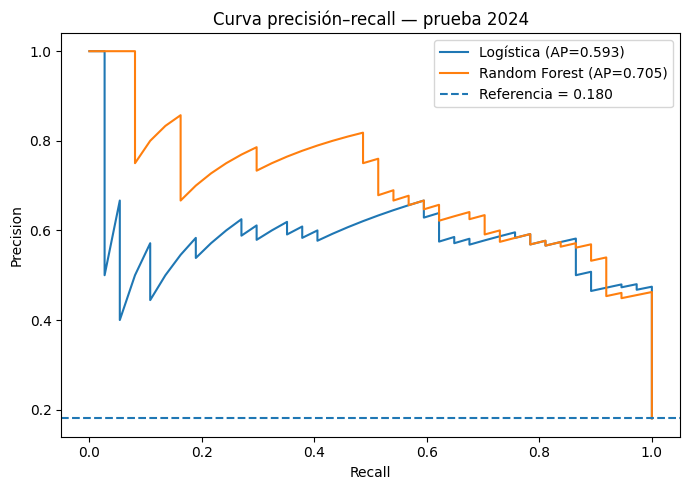

In [19]:
p_logit, r_logit, _ = precision_recall_curve(y_test, proba_test_logit)
p_rf, r_rf, _ = precision_recall_curve(y_test, proba_test_rf)

plt.figure(figsize=(7,5))
plt.plot(r_logit, p_logit, label=f"Logística (AP={average_precision_score(y_test, proba_test_logit):.3f})")
plt.plot(r_rf, p_rf, label=f"Random Forest (AP={average_precision_score(y_test, proba_test_rf):.3f})")
plt.axhline(y_test.mean(), linestyle="--", label=f"Referencia = {y_test.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva precisión–recall — prueba 2024")
plt.legend()
plt.tight_layout()
plt.show()

Análisis preliminar de importancia de variables
Para el Random Forest se revisa la importancia de variables. Esta salida es interpretativa, no causal: una variable importante para predecir no implica que provoque el cierre.

,importancia
meses_activos,0.252071
vuelos,0.176900
sillas,0.138264
horas_bloque,0.115565
pasajeros,0.109066
vuelos_mes,0.056741
pax_por_vuelo,0.044572
tendencia_ocupacion,0.034662
factor_ocupacion,0.034588
distancia,0.025469


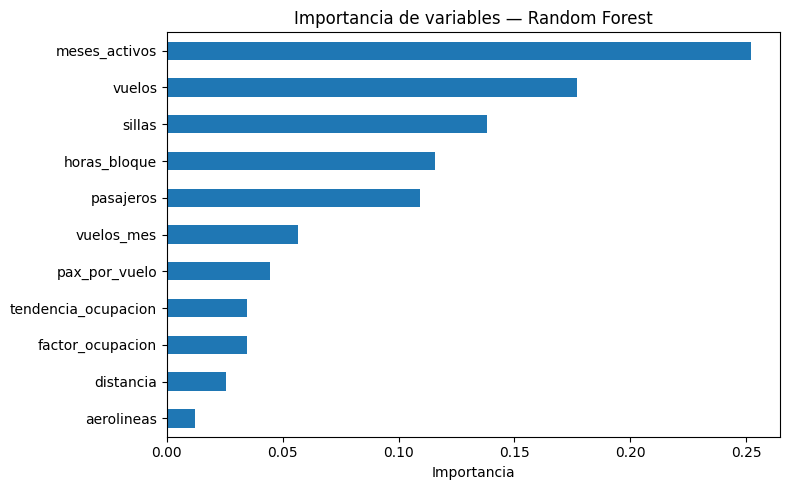

In [20]:
rf_model = rf.named_steps["model"]

importancias = (
    pd.Series(rf_model.feature_importances_, index=features)
      .sort_values(ascending=False)
)

display(importancias.to_frame("importancia"))

plt.figure(figsize=(8,5))
importancias.sort_values().plot(kind="barh")
plt.xlabel("Importancia")
plt.title("Importancia de variables — Random Forest")
plt.tight_layout()
plt.show()

Errores concretos
Se revisan falsos positivos y falsos negativos del modelo Random Forest. Esto permite identificar qué tipo de error debe estudiarse antes del cierre del proyecto.

In [21]:
pred_rf_test = (proba_test_rf >= umbral_rf).astype(int)

errores = test[[
    "Año", "ruta_id", "ruta_nombre", "cierre_12m"
]].copy()
errores["prob_cierre"] = proba_test_rf
errores["prediccion"] = pred_rf_test
errores["tipo_error"] = np.select(
    [
        (errores["cierre_12m"] == 1) & (errores["prediccion"] == 0),
        (errores["cierre_12m"] == 0) & (errores["prediccion"] == 1)
    ],
    ["Falso negativo", "Falso positivo"],
    default="Correcto"
)

display(
    errores[errores["tipo_error"] != "Correcto"]
    .sort_values("prob_cierre", ascending=False)
    .head(20)
)

,Año,ruta_id,ruta_nombre,cierre_12m,prob_cierre,prediccion,tipo_error
713,2024,CLO-IBE,SANTIAGO DE CALI - IBAGUÉ,0.0,0.950760,1,Falso positivo
720,2024,CLO-PEI,SANTIAGO DE CALI - PEREIRA,0.0,0.924771,1,Falso positivo
699,2024,BOG-VAL,"BOGOTÁ, D.C. - VALENCIA",0.0,0.917737,1,Falso positivo
736,2024,CTG-MTR,CARTAGENA DE INDIAS - MONTERÍA,0.0,0.898643,1,Falso positivo
660,2024,BOG-CFB,"BOGOTÁ, D.C. - MORALES",0.0,0.813834,1,Falso positivo
715,2024,CLO-LET,SANTIAGO DE CALI - LETICIA,0.0,0.803481,1,Falso positivo
744,2024,EOH-EYP,MEDELLÍN - YOPAL,0.0,0.780639,1,Falso positivo
602,2024,9DI-SJE,SAN FELIPE - SAN JOSÉ DEL GUAVIARE,0.0,0.766569,1,Falso positivo
609,2024,ACR-LET,SOLANO - LETICIA,0.0,0.750617,1,Falso positivo
656,2024,BGA-VUP,BUCARAMANGA - VALLEDUPAR,0.0,0.742216,1,Falso positivo


Diccionario mínimo de variables construidas

| Variable | Significado | Unidad |
|---|---|---|
| `ruta_id` | Identificador de la conexión entre dos aeropuertos | Código |
| `Año` | Año de predicción | Año |
| `pasajeros` | Pasajeros a bordo acumulados en el año | Personas |
| `sillas` | Sillas ofrecidas acumuladas | Sillas |
| `vuelos` | Vuelos regulares acumulados | Vuelos |
| `horas_bloque` | Horas bloque acumuladas | Horas |
| `distancia` | Distancia ortodrómica entre origen y destino | Km |
| `meses_activos` | Número de meses con operación | Meses |
| `aerolineas` | Aerolíneas que operaron la ruta durante el año | Número |
| `factor_ocupacion` | Pasajeros / sillas | Proporción |
| `pax_por_vuelo` | Pasajeros / vuelos | Personas |
| `vuelos_mes` | Vuelos / meses activos | Vuelos/mes |
| `tendencia_ocupacion` | Pendiente anual aproximada del factor de ocupación | Puntos proporcionales/año |
| `cierre_12m` | No operación durante el año siguiente | 0/1 |